# Neural File Search: experiments

This notebook explains and visualises the experiments behind the project. The heavy lifting
is done by the scripts; this notebook calls them and reads their outputs:

| Script | What it does |
|---|---|
| `prepare_data.py` | writes the 32 demo documents, 44 queries and the relevance labels |
| `search.py` | extraction -> chunking -> TF-IDF baseline and MiniLM + FAISS search |
| `evaluate.py` | computes Precision@5, Recall@5, MRR@5, latency and cache results into `results/` |

Run `python evaluate.py` before this notebook so the CSV files are current.

**Sections:** 1. corpus · 2. the two models on example queries · 3. retrieval metrics ·
4. where each model fails · 5. latency and caching · 6. conclusions and limitations

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)          # run from the project root
sys.path.insert(0, str(Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
from search import SearchEngine, load_model

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

# chart style: recessive axes, light grid, two fixed series colours
TFIDF_COLOR, MINILM_COLOR = "#2a78d6", "#eb6834"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "font.size": 10})
FIGURES = Path("results/figures"); FIGURES.mkdir(parents=True, exist_ok=True)

## 1. The corpus

The documents are **synthetic**: internal documents of a fictional delivery company, written for
this project (policies, reports, slide decks, spreadsheets). Each file type is split into natural
sections first (PDF page, DOCX heading, PPTX slide, CSV row), then into chunks of at most 120 words
with a 30-word overlap. 120 words is about 160 word-piece tokens, below MiniLM's 256-token limit
(a test checks that every sample chunk fits).

In [2]:
model = load_model()
engine = SearchEngine("data/sample_documents", model=model)
chunks = pd.DataFrame(engine.chunks)
overview = chunks.groupby("file_type").agg(files=("file_name", "nunique"), chunks=("chunk_id", "count"),
                                           avg_words=("text", lambda t: round(t.str.split().str.len().mean(), 1)))
print(f"{chunks.file_name.nunique()} files, {len(chunks)} chunks, embedding matrix {engine.semantic.embeddings.shape}")
overview

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

32 files, 155 chunks, embedding matrix (155, 384)


,files,chunks,avg_words
file_type,,,
csv,8,74,21.3
docx,8,24,48.2
pdf,8,25,61.8
pptx,8,32,19.3


In [3]:
# one chunk per file type, showing the metadata kept with every chunk
chunks.groupby("file_type").head(1)[["chunk_id", "file_type", "location", "text"]]

,chunk_id,file_type,location,text
0,api_integration_guide.docx#0,docx,section 'Authentication',Shipping API Integration Guide Authentication Merchants connect to the Brightfield shi...
3,board_update_q3_2026.pptx#0,pptx,slide 1,"Board Update Q3 2026. Prepared for the Board of Directors, October 2026"
18,data_retention_policy.pdf#0,pdf,page 1,Data Retention Policy Principles We keep personal data only for as long as necessary f...
28,fleet_vehicles.csv#0,csv,row 1,vehicle id: V-101; vehicle type: Panel van 3.5t; fuel type: Diesel; depot: Amsterdam; ...


## 2. The two models on example queries

* **Model A, TF-IDF:** NLTK tokenisation, stopword removal and lemmatisation, then a sparse
  TF-IDF vector per chunk and cosine similarity. It can only match words that literally appear.
* **Model B, MiniLM + FAISS:** `all-MiniLM-L6-v2` turns each chunk (original text, no stopword
  removal) into a 384-dimensional unit vector. A FAISS `IndexFlatIP` returns the vectors with the
  highest inner product, which for unit vectors equals cosine similarity. The search is exact; no
  approximation is used.

Both models score the same chunks. Each file is then represented by its best chunk, so a file can
appear only once in the top 5.

In [4]:
def compare(query, k=5):
    rows = []
    for mode in ["tfidf", "minilm"]:
        for r in engine.search(query, mode, k):
            rows.append({"model": mode, "rank": r["rank"], "file": r["file_name"],
                         "location": r["location"], "score": r["score"]})
    return pd.DataFrame(rows).pivot(index="rank", columns="model", values=["file", "score"])

print("Keyword query: both models should do well")
compare("forklift certification")

Keyword query: both models should do well


file                                score        
model                                 minilm                        tfidf  minilm   tfidf
rank                                                                                     
1                warehouse_safety_manual.pdf         training_courses.csv  0.7183  0.4501
2                       training_courses.csv  warehouse_safety_manual.pdf  0.6322  0.3887
3      cybersecurity_awareness_training.pptx                          NaN  0.2844     NaN
4                      hiring_plan_2027.pptx                          NaN  0.2688     NaN
5                      supplier_register.csv                          NaN  0.2664     NaN

In [5]:
print("Paraphrase: no content word in common with 'paternity leave' in the policy")
compare("how much time off do new dads get when a baby is born")

Paraphrase: no content word in common with 'paternity leave' in the policy


file                                       score        
model                              minilm                               tfidf  minilm   tfidf
rank                                                                                         
1               employee_leave_policy.pdf             sales_kickoff_2026.pptx  0.6285   0.262
2      new_hire_onboarding_checklist.docx  new_hire_onboarding_checklist.docx  0.1962  0.2547
3         delivery_operations_review.pptx     delivery_operations_review.pptx  0.1753  0.2505
4             vendor_contract_summary.pdf        marketing_campaign_plan.docx  0.1573   0.197
5             warehouse_safety_manual.pdf                training_courses.csv  0.1569  0.1535

Why rank **files** rather than chunks? CSV files have one chunk per row, so at chunk level a single
spreadsheet can take all five places. The cell below shows the raw chunk ranking for a query about
vehicles.

In [6]:
hits = engine.search_chunks("which vehicles run on diesel", "minilm")[:5]
pd.DataFrame([{**{k: engine.chunks[i][k] for k in ["file_name", "location"]}, "score": round(s, 3)} for i, s in hits])

,file_name,location,score
0,supplier_register.csv,row 4,0.453
1,meeting_minutes_fleet_electrification.docx,section 'Decisions and Next Steps',0.439
2,fleet_vehicles.csv,row 6,0.426
3,fleet_vehicles.csv,row 2,0.411
4,fleet_vehicles.csv,row 1,0.410


## 3. Retrieval metrics

**Setup.** 44 queries: 11 exact-keyword, 20 paraphrased questions, 8 short ambiguous queries and
5 queries with no relevant document. Relevance labels are binary, at document level, and were
written together with the queries before either model was run (`data/relevance_labels.csv`).

* **Precision@5** = relevant files in the top 5 / 5
* **Recall@5** = relevant files in the top 5 / all relevant files
* **MRR@5** = mean of 1 / (rank of the first relevant file in the top 5), counting 0 if none is there

Most queries have only one or two relevant files, so **even a perfect system cannot exceed
P@5 = 0.29** on this set (`max_possible_precision_at_5`, shown as "max" under the P@5 chart). MRR@5 and Recall@5 are therefore the more
informative metrics here.

In [7]:
metrics = pd.read_csv("results/retrieval_metrics.csv")
metrics[metrics.model != "MiniLM + NumPy cosine (diagnostic)"].drop(columns=["mean_results_returned"])

,query_group,model,n_queries,precision_at_5,recall_at_5,mrr,max_possible_precision_at_5,mean_top1_score
0,all answerable,TF-IDF + cosine,39,0.2154,0.7350,0.6598,0.2923,0.2954
1,all answerable,MiniLM + FAISS,39,0.2718,0.9466,0.9111,0.2923,0.5129
3,keyword,TF-IDF + cosine,11,0.2364,0.9545,0.9545,0.2545,0.4177
4,keyword,MiniLM + FAISS,11,0.2545,1.0000,1.0000,0.2545,0.6315
6,paraphrase,TF-IDF + cosine,20,0.1400,0.5917,0.4200,0.2400,0.2166
7,paraphrase,MiniLM + FAISS,20,0.2200,0.9333,0.8517,0.2400,0.4574
9,ambiguous,TF-IDF + cosine,8,0.3750,0.7917,0.8542,0.4750,0.3241
10,ambiguous,MiniLM + FAISS,8,0.4250,0.9062,0.9375,0.4750,0.4886
12,no_answer,TF-IDF + cosine,5,NaN,NaN,NaN,NaN,0.1313
13,no_answer,MiniLM + FAISS,5,NaN,NaN,NaN,NaN,0.2689


In [8]:
comparison = pd.read_csv("results/model_comparison.csv")
overall = comparison[comparison.query_group == "all answerable"].set_index("metric")
p5 = overall.loc["precision_at_5"]
relative = (p5.minilm_faiss - p5.tfidf) / p5.tfidf * 100
print(f"Precision@5: TF-IDF {p5.tfidf:.3f} -> MiniLM {p5.minilm_faiss:.3f}")
print(f"  absolute difference: {(p5.minilm_faiss - p5.tfidf) * 100:+.1f} percentage points "
      f"(95% bootstrap CI {p5.diff_95ci_low_points:+.1f} to {p5.diff_95ci_high_points:+.1f})")
print(f"  relative improvement: {relative:+.1f}%")
comparison

Precision@5: TF-IDF 0.215 -> MiniLM 0.272
  absolute difference: +5.6 percentage points (95% bootstrap CI +2.0 to +9.7)
  relative improvement: +26.2%


,query_group,metric,n_queries,tfidf,minilm_faiss,difference_points,relative_improvement_pct,diff_95ci_low_points,diff_95ci_high_points,queries_minilm_better,queries_tfidf_better,queries_tied
0,all answerable,precision_at_5,39,0.2154,0.2718,5.64,26.2,2.05,9.74,12,2,25
1,all answerable,recall_at_5,39,0.7350,0.9466,21.15,28.8,9.19,34.19,12,2,25
2,all answerable,mrr,39,0.6598,0.9111,25.13,38.1,11.79,38.63,15,2,22
3,keyword,precision_at_5,11,0.2364,0.2545,1.82,7.7,0.00,5.45,1,0,10
4,keyword,recall_at_5,11,0.9545,1.0000,4.55,4.8,0.00,13.64,1,0,10
5,keyword,mrr,11,0.9545,1.0000,4.55,4.8,0.00,13.64,1,0,10
6,paraphrase,precision_at_5,20,0.1400,0.2200,8.00,57.1,4.00,12.00,8,0,12
7,paraphrase,recall_at_5,20,0.5917,0.9333,34.17,57.7,15.00,55.00,8,0,12
8,paraphrase,mrr,20,0.4200,0.8517,43.17,102.8,20.17,63.83,12,1,7
9,ambiguous,precision_at_5,8,0.3750,0.4250,5.00,13.3,-7.50,17.50,3,2,3


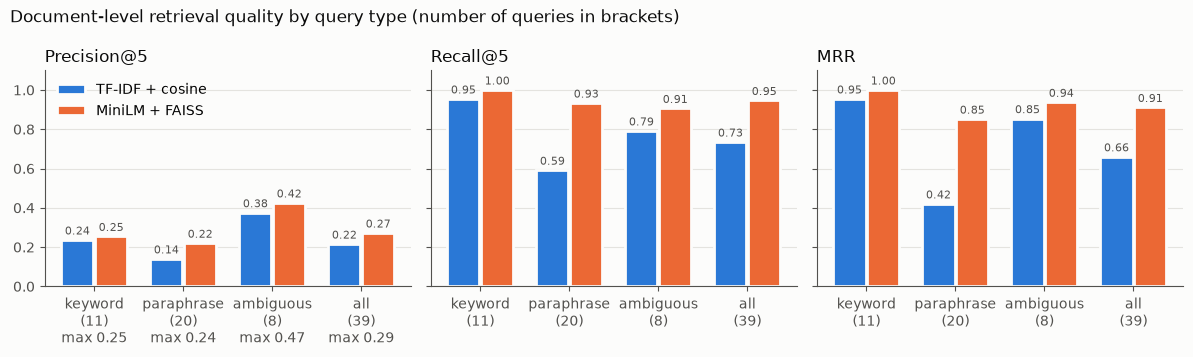

In [9]:
groups = ["keyword", "paraphrase", "ambiguous", "all answerable"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (metric, title) in zip(axes, [("precision_at_5", "Precision@5"), ("recall_at_5", "Recall@5"), ("mrr", "MRR")]):
    for offset, (label, color) in zip([-0.19, 0.19], [("TF-IDF + cosine", TFIDF_COLOR), ("MiniLM + FAISS", MINILM_COLOR)]):
        values = [metrics.query("query_group == @g and model == @label")[metric].iloc[0] for g in groups]
        bars = ax.bar([i + offset for i in range(len(groups))], values, width=0.36, color=color,
                      label=label, edgecolor="#fcfcfb", linewidth=2)
        ax.bar_label(bars, fmt="%.2f", fontsize=8, color=MUTED, padding=2)
    ticks = ["keyword\n(11)", "paraphrase\n(20)", "ambiguous\n(8)", "all\n(39)"]
    if metric == "precision_at_5":   # the ceiling explains why P@5 values are small
        ceilings = [metrics.query("query_group == @g")["max_possible_precision_at_5"].iloc[0] for g in groups]
        ticks = [f"{t}\nmax {c:.2f}" for t, c in zip(ticks, ceilings)]
    ax.set_title(title, color=INK, loc="left")
    ax.set_xticks(range(len(groups)), ticks)
    ax.set_ylim(0, 1.1); ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Document-level retrieval quality by query type (number of queries in brackets)", color=INK, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES / "retrieval_by_query_type.png", dpi=150)
plt.show()

**Reading the chart.** On exact-keyword queries the two models are almost tied: TF-IDF is a strong
baseline when the user knows the vocabulary. The gap comes from paraphrased questions, where
TF-IDF often finds no overlapping word or matches an unimportant one (MRR@5 0.42 vs 0.85).

How large the gap looks depends on the mix of queries. A query set made mostly of keyword
searches would show a much smaller improvement.

## 4. Where each model fails

In [10]:
per_query = pd.read_csv("results/per_query_results.csv")
wide = per_query[per_query.model.isin(["tfidf", "minilm"])].pivot(index=["query_id", "query_type", "query"],
                                                               columns="model", values="reciprocal_rank")
print("Queries where TF-IDF ranks the first relevant file higher than MiniLM:")
display(wide[wide.tfidf > wide.minilm])
print("Queries where MiniLM puts no relevant file in the top 5:")
display(wide[wide.minilm == 0])

Queries where TF-IDF ranks the first relevant file higher than MiniLM:


,,model,minilm,tfidf
query_id,query_type,query,,
Q31,paraphrase,under what conditions can we end the agreement with our hosting provider,0.2,1.0
Q38,ambiguous,safety,0.5,1.0


Queries where MiniLM puts no relevant file in the top 5:


,,model,minilm,tfidf
query_id,query_type,query,,
Q24,paraphrase,how can an online shop plug its systems into ours,0.0,0.0


In [11]:
# what did both models return for the query they both failed?
per_query.query("query_id == 'Q24' and model in ['tfidf', 'minilm']")[["model", "top5_files", "relevant_files"]]

,model,top5_files,relevant_files
69,tfidf,marketing_campaign_plan.docx; information_security_policy.pdf; incident_postmortem_tra...,api_integration_guide.docx
70,minilm,remote_work_guidelines.pdf; service_catalog.csv; cybersecurity_awareness_training.pptx...,api_integration_guide.docx


**No-answer queries.** MiniLM always returns *k* results because every vector has some
similarity to every other vector. TF-IDF returns nothing when no word overlaps. A score threshold
could let MiniLM answer "nothing found". The chart compares the top-1 scores of answerable and
unanswerable queries. The groups only just overlap (highest unanswerable 0.310, lowest answerable
0.309), so the best single cut-off would misclassify one of the 44 queries. No threshold is used:
it would be picked by looking at these evaluation queries and would rest on only 5 unanswerable ones.

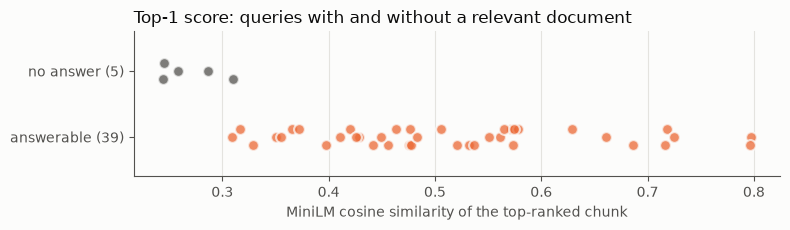

lowest answerable top-1 score: 0.309; highest no-answer top-1 score: 0.310; answerable queries below 0.32: 2


In [12]:
mini = per_query[per_query.model == "minilm"].copy()
mini["group"] = mini.query_type.where(mini.query_type == "no_answer", "answerable")
fig, ax = plt.subplots(figsize=(8, 2.4))
for y, (group, color) in enumerate([("answerable", MINILM_COLOR), ("no_answer", MUTED)]):
    scores = mini[mini.group == group].top1_score
    jitter = [((i % 3) - 1) * 0.12 for i in range(len(scores))]  # fixed offsets so equal scores stay visible
    ax.scatter(scores, [y + j for j in jitter], s=60, color=color, alpha=0.75, edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
ax.set_yticks([0, 1], [f"answerable ({(mini.group == 'answerable').sum()})", f"no answer ({(mini.group == 'no_answer').sum()})"])
ax.set_ylim(-0.6, 1.6); ax.grid(axis="y", visible=False)
ax.set_xlabel("MiniLM cosine similarity of the top-ranked chunk")
ax.set_title("Top-1 score: queries with and without a relevant document", color=INK, loc="left")
fig.tight_layout(); fig.savefig(FIGURES / "no_answer_scores.png", dpi=150); plt.show()
answerable = mini[mini.group == "answerable"].top1_score
print(f"lowest answerable top-1 score: {answerable.min():.3f}; highest no-answer top-1 score: "
      f"{mini[mini.group == 'no_answer'].top1_score.max():.3f}; answerable queries below 0.32: {(answerable < 0.32).sum()}")

## 5. Latency and caching

All timings are medians over repeated runs on a laptop CPU (no GPU), measured by `evaluate.py`.
Cold start, indexing and per-query search are measured **separately** because they happen at
different times: once per process, once per document change, and once per query.

In [13]:
latency = pd.read_csv("results/latency.csv")
latency[["scenario", "what_is_timed", "measurements", "median_ms", "p95_ms", "notes"]]

,scenario,what_is_timed,measurements,median_ms,p95_ms,notes
0,cold_start_model_load,new Python process: import libraries + load MiniLM from disk,3,32249.145,32732.766,excludes the one-time ~90 MB download; first run after boot is slowest
1,cold_start_first_encode,first MiniLM forward pass in a new process,3,30.991,31.468,"one-time PyTorch warm-up, not repeated on later queries"
2,index_build_no_cache,extract + chunk + embed all files + build FAISS index,3,4493.452,4495.152,155 chunks from 32 files
3,index_load_from_cache,hash files + load cached chunks/embeddings + load FAISS index,10,66.737,438.689,files unchanged since the cache was written
4,tfidf_fit,fit TfidfVectorizer (NLTK preprocessing) on all chunks,5,234.406,281.895,NaN
5,query_tfidf,end-to-end query: preprocess + sparse cosine over all chunks + rank files,880,2.675,3.506,44 queries x 20 repeats
6,query_minilm_faiss,end-to-end query: MiniLM query embedding + FAISS search + rank files,880,22.031,29.834,44 queries x 20 repeats; query cache disabled
7,query_minilm_faiss_cached_query,"same, but the query embedding comes from the in-memory query cache",880,0.183,0.258,only helps when the exact same query text is repeated
8,search_step_faiss_flat,FAISS IndexFlatIP search only (vector already computed),4400,0.045,0.057,"155 vectors; retrieves all chunks, as used for ranking"
9,search_step_numpy_cosine,NumPy matrix-vector cosine + argsort only,4400,0.116,0.208,155 vectors


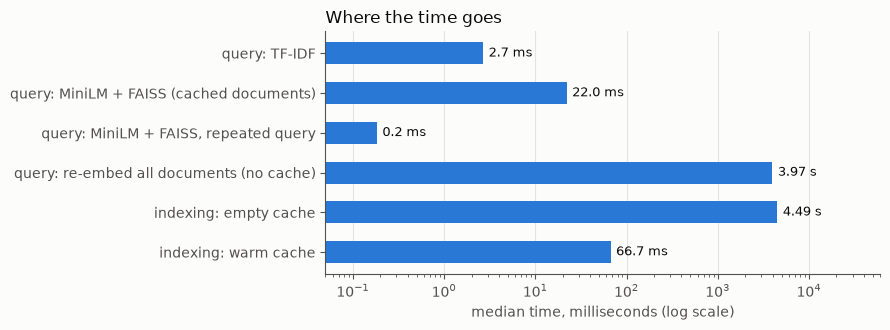

In [14]:
show = ["query_tfidf", "query_minilm_faiss", "query_minilm_faiss_cached_query",
        "query_without_embedding_cache", "index_build_no_cache", "index_load_from_cache"]
labels = {"query_tfidf": "query: TF-IDF", "query_minilm_faiss": "query: MiniLM + FAISS (cached documents)",
          "query_minilm_faiss_cached_query": "query: MiniLM + FAISS, repeated query",
          "query_without_embedding_cache": "query: re-embed all documents (no cache)",
          "index_build_no_cache": "indexing: empty cache", "index_load_from_cache": "indexing: warm cache"}
data = latency.set_index("scenario").loc[show, "median_ms"][::-1]
fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.barh([labels[s] for s in data.index], data.values, color=TFIDF_COLOR, height=0.55)
ax.bar_label(bars, labels=[f"{v:,.1f} ms" if v < 1000 else f"{v / 1000:.2f} s" for v in data.values],
             padding=4, fontsize=9, color=INK)
ax.set_xscale("log"); ax.set_xlim(0.05, 60000); ax.grid(axis="y", visible=False)
ax.set_xlabel("median time, milliseconds (log scale)")
ax.set_title("Where the time goes", color=INK, loc="left")
fig.tight_layout(); fig.savefig(FIGURES / "latency.png", dpi=150); plt.show()

**Interpreting the latency results**

* **Most of a ~22 ms MiniLM query is embedding the query.** A repeated query, whose embedding comes
  from the query cache, takes about 0.2 ms, and the search step alone takes well under 1 ms for 155
  vectors with either FAISS or NumPy brute force.
* **The disk cache saves indexing time, not query time.** Storing document embeddings is how any
  vector search works, so re-embedding all 155 chunks for every query (roughly 4 s) is only a
  reference point. The cache's own effect: re-indexing unchanged files takes about 67 ms instead
  of about 4.5 s, and only an edited file is re-embedded.
* On 10k–100k synthetic vectors, exact FAISS (`IndexFlatIP`, single query) was *not* faster than
  NumPy's BLAS matrix-vector product on this machine. A likely reason, not measured here: for fewer
  than 20 queries per call, FAISS's exact search does not use BLAS and splits its work across
  queries, so one query runs on one thread. FAISS becomes useful with batched queries, approximate
  indexes (IVF, HNSW) and larger collections. These were not needed for 155 chunks.
* The slowest step a user experiences is **cold start** (importing PyTorch and loading the model in
  a new process). The Streamlit app pays it once and keeps the model in memory.

In [15]:
pd.read_csv("results/cache_effectiveness.csv")

,step,files_seen,files_from_cache,files_processed,index_from_cache,chunks,seconds
0,1. empty cache (first indexing),32,0,32,False,155,5.667
1,2. same files again (warm cache),32,32,0,True,155,0.856
2,3. one file edited (support_tickets.csv),32,31,1,False,156,0.334
3,4. chunk size changed 120 -> 80 words,32,0,32,False,158,5.416
4,5. back to original settings (old entries reused),32,32,0,True,156,0.565
5,6. unsupported .txt file added,32,32,0,True,156,0.066


The cache has two levels. Chunks are keyed by a SHA-256 hash of each file's bytes, its name, chunk
size, overlap and a pipeline version; no model is involved, so TF-IDF never depends on MiniLM.
Embeddings are keyed by the chunk key plus a fingerprint of the loaded model's weights. Editing one
file re-embeds only that file (step 3). Changing the chunk size re-embeds everything (step 4).
Cached vectors are bit-identical to the first run (`results/summary.json`). The table was measured
before the cache was split into two levels; the split gives the same file counts in every step.

## 6. Conclusions and limitations

**What the experiment supports**
* On this corpus MiniLM + FAISS retrieved the right file first far more often than TF-IDF
  (MRR@5 0.66 -> 0.91). The gain is concentrated in paraphrased questions.
* Precision@5 rose from 0.215 to 0.272. That is +5.6 percentage points, or +26% relative, and the
  95% bootstrap CI of the difference excludes zero. P@5 is capped at 0.29 by the small number of
  relevant files per query, so the absolute numbers look small.
* A MiniLM query takes about 22 ms, almost all of it embedding the query. The disk cache saves
  indexing time: unchanged files are re-indexed in about 67 ms instead of about 4.5 s.

**Limitations**
* The corpus is small (32 files, 155 chunks) and synthetic, and the queries and labels were written
  by the same author as the documents. Paraphrase queries were deliberately worded differently from
  the documents, which is the situation where embeddings are expected to help.
* 39 answerable queries give wide confidence intervals; per-type results (8–20 queries) are noisier still.
* Binary labels only; no graded relevance or second annotator to measure agreement.
* No score threshold, so MiniLM always returns results even when nothing is relevant.
* No hybrid (BM25 + embeddings) or re-ranking baseline; these would be natural next steps.